# Figure 16. Results in large-scale simulations (a) End-to-end Performance

# Simulation Main Figure Visualization

## 1. Setup and Configuration

In [1]:
import torch
import os
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict
from Suika import analyze_job_statistics, parse_cluster_config

# --- Configuration ---
cluster = "clusterA"
policies = ["suika", "sia", "rubick", "fcfs"]
traces = [1, 2, 3, 4] # Traces to process
config_path = "../configs/cluster64.json"
total_n_acc = parse_cluster_config(config_path)[0].get_total_acc_num()

policy_map = {
    "suika": "Suika",
    "sia": "Sia",
    "rubick": "Rubick",
    "dp": "Suika-DP",
    "metis": "Suika-Metis",
    "fcfs": "FIFO",
}

policy_styles = {
    "suika":  {"color": "#34495e", "hatch": ""},
    "sia":    {"color": "#e67e22", "hatch": "/"},
    "rubick": {"color": "#f1c40f", "hatch": "x"},
    "dp":  {"color": "#95a5a6", "hatch": "+"},
    "metis":     {"color": "#3498db", "hatch": "."},
    "fcfs":   {"color": "#e74c3c", "hatch": "-"},
}

all_stats = defaultdict(lambda: defaultdict(dict))

print(f"Cluster: {cluster} ({total_n_acc} GPUs)")
print(f"Traces: {traces}")

/home/fake/.local/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Cluster: clusterA (64 GPUs)
Traces: [1, 2, 3, 4]


## 2. Data Loading and Processing

Now, we load the data for each policy and process it using the event-driven function defined above.

In [2]:
print("Loading data...")
for trace in traces:
    print(f"--- Processing Trace {trace} ---")
    for policy in policies:
        file_path = f"../results/simu-trace{trace}/{policy}-simu-trace{trace}.pth"
        try:
            stats = torch.load(file_path, weights_only=False)
            analyzed = analyze_job_statistics(stats)
            
            avg_jct = analyzed.get("avg_jct")

            if avg_jct is not None:
                all_stats[trace][policy] = {'jct': avg_jct}
                print(f"  - Loaded {policy}: JCT={avg_jct:.2f}")
            else:
                print(f"  - WARNING: Could not find JCT data for {policy}")

        except FileNotFoundError:
            print(f"  - SKIPPING: File not found at {file_path}")
        except Exception as e:
            print(f"  - ERROR: Failed to load or process {file_path}: {e}")
print("\nData loading complete.")

Loading data...
--- Processing Trace 1 ---
  - Loaded suika: JCT=2467.73
  - Loaded sia: JCT=3001.09
  - Loaded rubick: JCT=2857.97
  - Loaded fcfs: JCT=3643.90
--- Processing Trace 2 ---
  - Loaded suika: JCT=1908.29
  - Loaded sia: JCT=2701.00
  - Loaded rubick: JCT=2545.87
  - Loaded fcfs: JCT=3105.68
--- Processing Trace 3 ---
  - Loaded suika: JCT=2438.01
  - Loaded sia: JCT=3312.27
  - Loaded rubick: JCT=3466.00
  - Loaded fcfs: JCT=4541.26
--- Processing Trace 4 ---
  - Loaded suika: JCT=1968.64
  - Loaded sia: JCT=2379.99
  - Loaded rubick: JCT=2805.55
  - Loaded fcfs: JCT=3053.99

Data loading complete.


## 3. Visualization

This section generates the main figure, which is composed of two subplots separated by a vertical line:
- **Left Plot**: Grouped bar charts for Average JCT and Average Weighted JCT.
- **Right Plot**: A bar chart for Cluster Utilization.

A shared legend is placed at the top.

Plot saved as '../fig/jct_comparison_simulation.pdf'


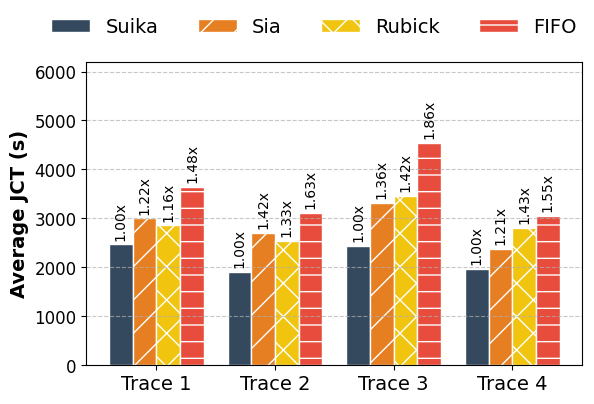


==== Average Speedup of Suika over ====
Suika   1.00x
Sia     1.30x
Rubick  1.33x
FIFO    1.63x


In [3]:
def plot_jct_bar_chart(stats, policy_map, policy_styles, traces):
    """Plots a grouped bar chart of JCT for multiple traces and policies."""
    
    valid_policies = [p for p in policies if any(p in stats.get(t, {}) for t in traces)]
    if not valid_policies:
        print("No policies with data to plot.")
        return

    fig, ax = plt.subplots(figsize=(6, 4))
    
    n_traces = len(traces)
    n_policies = len(valid_policies)
    
    x = np.arange(n_traces)
    width = 0.8 / n_policies

    avg_speedup = {}
    ref_p = valid_policies[0]  # Reference policy for speedup calculation
    

    for i, policy in enumerate(valid_policies):
        # Get JCT for this policy across all traces, using NaN for missing data
        jct_values = [stats.get(trace, {}).get(policy, {}).get('jct', np.nan) for trace in traces]
        
        style = policy_styles.get(policy, {})
        offset = (i - (n_policies - 1) / 2) * width
        
        bars = ax.bar(x + offset, jct_values, width, 
                      label=policy_map.get(policy, policy.upper()),
                      color=style.get("color"), hatch=style.get("hatch"), edgecolor='white')

        # Add relative performance markers
        for trace_idx, trace in enumerate(traces):
            ref_jct = stats.get(trace, {}).get(ref_p, {}).get('jct', None)
            
            height = bars[trace_idx].get_height()
            if not np.isnan(height) and ref_jct is not None and ref_jct > 0:
                relative_perf = height / ref_jct
                ax.annotate(f'{relative_perf:.2f}x',
                            xy=(bars[trace_idx].get_x() + bars[trace_idx].get_width() / 2, height),
                            xytext=(0, 3),  # 3 points vertical offset
                            textcoords="offset points",
                            ha='center', va='bottom', fontsize=10, rotation=90)
            
            avg_speedup.setdefault(policy, []).append(relative_perf if ref_jct else np.nan)
    for policy, speeds in avg_speedup.items():
        speeds = [s for s in speeds if not np.isnan(s)]
        if speeds:
            avg_speedup[policy] = np.mean(speeds)
        else:
            avg_speedup[policy] = np.nan

    ax.set_ylabel('Average JCT (s)', fontsize=14, fontweight='bold'
                  )
    ax.set_xticks(x)
    ax.set_xticklabels([f'Trace {i+1}' for i in range(n_traces)], fontsize=14, fontweight='normal')
    ax.tick_params(axis='y', labelsize=12)
    ax.grid(True, axis='y', linestyle='--', alpha=0.7)

    current_ylim = ax.get_ylim()
    ax.set_ylim(current_ylim[0], current_ylim[1] * 1.3)

    handles, labels = ax.get_legend_handles_labels()
    fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.53, 1.02),
               ncol=len(valid_policies), fontsize=14, frameon=False)

    fig.tight_layout(rect=[0, 0, 1, 0.9], pad=1.0)
    
    fig_dir = "../fig"
    os.makedirs(fig_dir, exist_ok=True)
    filename = f"{fig_dir}/jct_comparison_simulation.pdf"
    plt.savefig(filename, dpi=600, bbox_inches="tight")
    print(f"Plot saved as '{filename}'")
    
    plt.show()
    
    print(f"\n==== Average Speedup of {policy_map.get(ref_p, ref_p)} over ====")
    for policy, speed in avg_speedup.items():
        if not np.isnan(speed):
            print(f"{policy_map.get(policy, policy):6}  {speed:.2f}x")
        else:
            print(f"{policy_map.get(policy, policy):6}  N/A")

# --- Generate Plot ---
plot_jct_bar_chart(all_stats, policy_map, policy_styles, traces)